# Dermoscopy Copilot — 01. Train/Validation/Test Splits

**Course:** Human-Centered Artificial Intelligence (HCAI) · MSc in Biomedical Engineering · University of Coimbra · **Group 13:** Carolina Garrido, Sara Santos, Sara Seco

## Purpose of this notebook

The data used throughout the project was prepared **once** with the script `preparar_dados.py`, which:

1. Downloads the **HAM10000** dataset (dermoscopic images and metadata) and the corresponding **lesion segmentation masks**;
2. Performs an initial exploratory analysis (class distribution and number of images per lesion);
3. Links each `image_id` to its image file;
4. Splits the data into **training (~70%)**, **validation (~15%)** and **test (~15%)** sets, stratified by diagnosis and grouped by lesion to prevent data leakage;
5. Saves the splits as CSV files (`splits/train.csv`, `splits/val.csv`, `splits/test.csv`), to be reused by the remaining notebooks.

**Note:** the split is performed only once, with a fixed seed (`random_state=42`), to ensure reproducibility.

This notebook **loads the splits generated by `preparar_dados.py`** and checks that they are valid. 

**Input:** `splits/train.csv`, `splits/val.csv`, `splits/test.csv` (columns `image_id`, `lesion_id`, `dx`).

## 1. Loading the splits

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Base path: go up one level if the notebook is inside the 'notebooks' folder
BASE_DIR = Path("..") if Path.cwd().name == "notebooks" else Path(".")

SPLITS_DIR = BASE_DIR / "splits"
splits = {s: pd.read_csv(SPLITS_DIR / f"{s}.csv") for s in ["train", "val", "test"]}

## 2. Exploratory analysis of the full dataset

Joining the three splits recovers the whole HAM10000 dataset. Two aspects are particularly relevant for the experimental design:

- **Class imbalance:** the number of images varies considerably across the seven diagnostic categories, which motivates the use of class weights and macro-averaged metrics (Balanced Accuracy, macro F1-score, etc.);
- **Multiple images per lesion:** a single lesion may have more than one image. If images of the same lesion end up in different splits, the model is evaluated on images nearly identical to those seen during training, which inflates performance estimates. The split is therefore performed **by lesion** rather than by image.

In [2]:
df = pd.concat(splits.values(), ignore_index=True)

print("Dataframe shape:", df.shape)  # expected: (10015, 3)
display(df.head())

print("\nNumber of images per diagnosis (class imbalance):")
print(df["dx"].value_counts())

print("\nNumber of lesions with N images (index = number of images per lesion):")
print(df["lesion_id"].value_counts().value_counts())

Dataframe shape: (10015, 3)


,image_id,lesion_id,dx
0,ISIC_0027419,HAM_0000118,bkl
1,ISIC_0025030,HAM_0000118,bkl
2,ISIC_0026769,HAM_0002730,bkl
3,ISIC_0025661,HAM_0002730,bkl
4,ISIC_0031633,HAM_0001466,bkl



Number of images per diagnosis (class imbalance):
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Number of lesions with N images (index = number of images per lesion):
count
1    5514
2    1423
3     490
4      34
5       5
6       4
Name: count, dtype: int64


## 3. Train / validation / test split

The data was divided into three splits:

| Split | Purpose | Approx. proportion |
|---|---|---|
| **Training** | Fitting the model parameters | ~70% |
| **Validation** | Hyperparameter selection and model tuning | ~15% |
| **Test** | Final evaluation, used only at the end | ~15% |

`StratifiedGroupKFold` was used, which simultaneously ensures:

- **Stratification** by diagnosis (`dx`), keeping similar class proportions across splits;
- **Grouping** by `lesion_id`, ensuring that all images of the same lesion fall in the same split.

The split was performed in two steps: first the test set was separated (1 of 7 folds ≈ 15%) and then, from the remainder, the validation set was separated (1 of 6 folds ≈ 14% of the total).

The table below shows the number of images and lesions in each split and the proportions actually obtained (`% of images`).

In [3]:
total = sum(len(d) for d in splits.values())

summary = pd.DataFrame({
    "images": {s: len(d) for s, d in splits.items()},
    "lesions": {s: d["lesion_id"].nunique() for s, d in splits.items()},
})
summary["% of images"] = (summary["images"] / total * 100).round(1)

print("Total images:", total)  # expected: 10015
display(summary)

Total images: 10015


,images,lesions,% of images
train,7153,5336,71.4
val,1431,1067,14.3
test,1431,1067,14.3


## 4. Check for data leakage

No lesion may appear in more than one split. Each set below must be empty (`set()`).

In [4]:
lesions = {s: set(d["lesion_id"]) for s, d in splits.items()}

print("Lesions shared train/test:", lesions["train"] & lesions["test"])
print("Lesions shared train/val: ", lesions["train"] & lesions["val"])
print("Lesions shared val/test:  ", lesions["val"] & lesions["test"])

Lesions shared train/test: set()
Lesions shared train/val:  set()
Lesions shared val/test:   set()


## 4. Class distribution per split

Because of the class imbalance of HAM10000, stratification should keep the proportion of each diagnosis similar across the three splits. All classes must be represented in the test set.

Number of images per class:


,train,val,test
dx,,,
nv,4789,958,958
mel,795,159,159
bkl,785,157,157
bcc,366,74,74
akiec,234,47,46
vasc,102,20,20
df,82,16,17


Percentage of each split:


,train,val,test
dx,,,
nv,67.0,66.9,66.9
mel,11.1,11.1,11.1
bkl,11.0,11.0,11.0
bcc,5.1,5.2,5.2
akiec,3.3,3.3,3.2
vasc,1.4,1.4,1.4
df,1.1,1.1,1.2


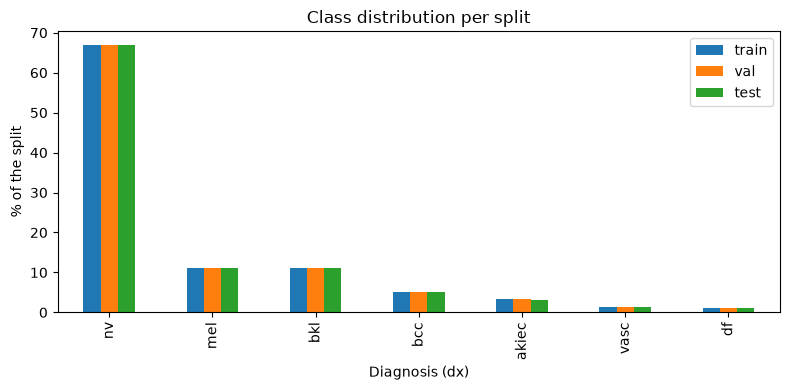

In [5]:
dist = pd.DataFrame({s: d["dx"].value_counts() for s, d in splits.items()}).fillna(0).astype(int)
dist_pct = (dist / dist.sum() * 100).round(1)

print("Number of images per class:")
display(dist)
print("Percentage of each split:")
display(dist_pct)

ax = dist_pct.plot(kind="bar", figsize=(8, 4))
ax.set_ylabel("% of the split")
ax.set_xlabel("Diagnosis (dx)")
ax.set_title("Class distribution per split")
plt.tight_layout()
plt.show()